<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/00_init_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import pandas as pd

DATA = '/content/drive/MyDrive/DataSets/raw'

In [9]:
# Load sample month from shared folder
df = pd.read_csv(f'{DATA}/2024/bikeshare-ridership-2024-01_Jan.csv')
df.head()

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
0,26682740,528,7041,2024-01-01 00:00:08,Edward St / Yonge St,7130.0,2024-01-01 00:08:56,Davenport Rd / Bedford Rd,7855,Casual,EFIT G5
1,26682742,1924,7245,2024-01-01 00:02:04,Tecumseth St / Queen St W - SMART,7259.0,2024-01-01 00:34:08,Lower Spadina Ave / Lake Shore Blvd W,2453,Casual,ICONIC
2,26682743,2741,7052,2024-01-01 00:03:25,Wellington St W / Bay St,7366.0,2024-01-01 00:49:06,Fort York Blvd / Bathurst St - SMART,7332,Member,ICONIC
3,26682744,353,7041,2024-01-01 00:03:39,Edward St / Yonge St,7418.0,2024-01-01 00:09:32,College Park - Yonge St Entrance,782,Member,ICONIC
4,26682746,2118,7721,2024-01-01 00:04:44,Widmer St / King St W,7721.0,2024-01-01 00:40:02,Widmer St / King St W,1008,Member,ICONIC


In [10]:
df.shape, df.size

((204879, 11), 2253669)

In [11]:
df.isna().sum()

,0
Trip_Id,0
Trip_Duration,0
Start_Station_Id,0
Start_Time,0
Start_Station_Name,0
End_Station_Id,89
End_Time,4
End_Station_Name,89
Bike_Id,0
User_Type,0


In [12]:
df_explore = df.copy()

In [13]:
pd.set_option("display.float_format", "{:,.0f}".format)

In [14]:
trip_duration = df_explore["Trip_Duration"]
trip_duration.describe()

,Trip_Duration
count,"204,879"
mean,901
std,"10,293"
min,0
25%,361
50%,574
75%,917
max,"2,320,126"


**Observations:**
1. minimum Trip_Duration = 0 : To check if these are at the same station (Start_Station_Id == End_Station_Id?)
2. max Trip_Duration = 2,320,126 : Very far from the value at 75% (so most likely an outlier?)

In [15]:
#trip_duration.value_counts().sort_index()

df_explore[df_explore["Trip_Duration"] > 2000].sort_values("Trip_Duration", ascending=False)

,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
135296,26837460,2320126,7269,2024-01-23 20:48:25,Toronto Eaton Centre (Yonge St) - SMART,"7,428",2024-02-19 17:17:11,Woodbine Ave / Lake Shore Blvd E,3914,Casual,ICONIC
119140,26818864,1580918,7671,2024-01-21 09:55:41,Yonge St / Montgomery Ave - SMART,"7,376",2024-02-08 17:04:19,Frobisher Ave / Lascelles Blvd,3706,Member,ICONIC
31570,26718463,1444010,7900,2024-01-05 20:04:59,Simcoe St / Elm St,"7,788",2024-01-22 13:11:49,Queens Quay E / Lower Jarvis St,540,Member,ICONIC
59239,26750557,1181645,7257,2024-01-10 18:35:20,Dundas St W / St. Patrick St,"7,163",2024-01-24 10:49:25,Yonge St / Wood St,5328,Member,ICONIC
98709,26795527,1109336,7022,2024-01-17 17:18:10,Simcoe St / Queen St W,"7,100",2024-01-30 13:27:06,Dundas St E / Regent Park Blvd,1722,Casual,ICONIC
...,...,...,...,...,...,...,...,...,...,...,...
18674,26703905,2001,7447,2024-01-04 08:33:49,Trent Ave / Danforth Ave,"7,332",2024-01-04 09:07:10,200 Bloor St E,7896,Member,EFIT G5
115032,26814212,2001,7713,2024-01-20 11:37:31,Temperance St / Bay St,"7,019",2024-01-20 12:10:52,Temperance St Station,3736,Member,ICONIC
66364,26758722,2001,7006,2024-01-11 18:03:42,Bay St / College St (East Side),"7,061",2024-01-11 18:37:03,Dalton Rd / Bloor St W,5920,Member,ICONIC
21158,26706753,2001,7118,2024-01-04 14:50:01,King St W / Bay St (East Side),"7,076",2024-01-04 15:23:22,York St / Queens Quay W,3500,Member,ICONIC


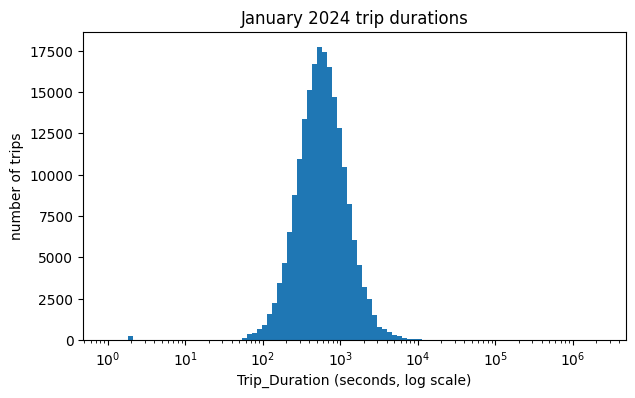

In [16]:
import numpy as np
import matplotlib.pyplot as plt
bins = np.logspace(0, np.log10(trip_duration.max()), 100)

plt.figure(figsize=(7, 4))
plt.hist(trip_duration[trip_duration > 0], bins=bins)
plt.xscale("log")
plt.xlabel("Trip_Duration (seconds, log scale)")
plt.ylabel("number of trips")
plt.title("January 2024 trip durations")
plt.show()

## This section loops over the raw files, profiles them and stores the profiles in new file

In [21]:
bins = np.logspace(0, 7, 141)        # 1 s to 10^7 s
hist_total = np.zeros(len(bins) - 1)

DUR_BINS = np.logspace(0, 7, 141)
# inside the loop, after reading df:
#   hist_total += np.histogram(df["Trip_Duration"].clip(lower=1), bins=bins)[0]

In [22]:
import pandas as pd
import numpy as np, glob, os

RENAME_2023 = {"Trip Id": "Trip_Id", "Trip  Duration": "Trip_Duration",
               "Start Station Id": "Start_Station_Id", "Start Time": "Start_Time",
               "Start Station Name": "Start_Station_Name", "End Station Id": "End_Station_Id",
               "End Time": "End_Time", "End Station Name": "End_Station_Name",
               "Bike Id": "Bike_Id", "User Type": "User_Type"}

def profile_month(path):
    df = pd.read_csv(path, low_memory=False)
    n_cols = len(df.columns)
    df.columns = [c.replace("\ufeff", "") for c in df.columns]      # remove any BOM left in 2023 headers
    schema = "2023" if "Trip Id" in df.columns else "2024+"         # was the file 2023 schema or 2024 or later?
    df = df.rename(columns=RENAME_2023)

    df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
    df["End_Time"] = pd.to_datetime(df["End_Time"], errors="coerce")
    col_tripduration = df["Trip_Duration"]
    same = df["Start_Station_Id"] == df["End_Station_Id"]
    elapsed = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()

    r = {"file": os.path.basename(path), "rows": len(df), "n_cols": n_cols, "schema": schema,
         "start_min": df["Start_Time"].min(), "start_max": df["Start_Time"].max(),
         "start_time_unparsed": df["Start_Time"].isna().sum(),       # dates that failed to parse
         "end_time_unparsed": df["End_Time"].isna().sum(),           # includes genuinely blank End_Time
         "duplicate_trip_id": df["Trip_Id"].duplicated().sum(),
         "nunique_stations_start": df["Start_Station_Id"].nunique(),
         "nunique_stations_end": df["End_Station_Id"].nunique(),
         "percent_casual": (df["User_Type"].astype(str).str.contains("Casual")).mean() * 100,
         "tripdur_zero": (col_tripduration == 0).sum(), "tripdur_negative": (col_tripduration < 0).sum(),
         "tripdur_p50": col_tripduration.quantile(.5), "tripdur_p99": col_tripduration.quantile(.99),
         "tripdur_p99_9": col_tripduration.quantile(.999), "tripdur_max": col_tripduration.max(),
         "short_lessthan60": (col_tripduration < 60).sum(),
         "short_lessthan60_same_station": ((col_tripduration < 60) & same).sum(),
         "long_greaterthan2h": (col_tripduration > 7200).sum(), "long_greaterthan3h": (col_tripduration > 10800).sum(),
         "long_greaterthan24h": (col_tripduration > 86400).sum(),
         "time_mismatch_greaterthan60s": ((elapsed - col_tripduration).abs() > 60).sum(),
         "end_before_start": (elapsed < 0).sum()}

    #for c in ["Start_Station_Id", "End_Station_Id", "End_Time", "Start_Station_Name", "End_Station_Name", "Bike_Model"]:
    #    r[f"miss_{c}"] = df[c].isna().sum() if c in df else np.nan
    #return r

    for c in ["Start_Station_Id", "End_Station_Id", "End_Time", "Start_Station_Name", "End_Station_Name", "Bike_Model"]:
      r[f"miss_{c}"] = df[c].isna().sum() if c in df else np.nan

    counts, _ = np.histogram(col_tripduration.clip(lower=1), bins=DUR_BINS)
    return r, counts

In [23]:
DATA = '/content/drive/MyDrive/DataSets'
RAW = f"{DATA}/raw"
PROFILE = f"{DATA}/profile"

In [25]:
files = sorted(glob.glob(f"{RAW}/**/*.csv", recursive=True))
print(len(files), "files")          # should print 39

rows = []
hist_total = np.zeros(len(DUR_BINS) - 1)

for f in files:
    r, counts = profile_month(f)
    rows.append(r)
    hist_total += counts
    print("done", os.path.basename(f), flush=True)

profile = pd.DataFrame(rows)
os.makedirs(f"{PROFILE}", exist_ok=True)
profile.to_csv(f"{PROFILE}/profile_by_month.csv", index=False)
np.save(f"{PROFILE}/tripdur_hist_total.npy", hist_total)
profile

39 files
done Bike share ridership 2023-01.csv
done Bike share ridership 2023-02.csv
done Bike share ridership 2023-03.csv
done Bike share ridership 2023-04.csv
done Bike share ridership 2023-05.csv
done Bike share ridership 2023-06.csv
done Bike share ridership 2023-07.csv
done Bike share ridership 2023-08.csv
done Bike share ridership 2023-09.csv
done Bike share ridership 2023-10.csv
done Bike share ridership 2023-11.csv
done Bike share ridership 2023-12.csv
done bikeshare-ridership-2024-01_Jan.csv
done bikeshare-ridership-2024-02_Feb.csv
done bikeshare-ridership-2024-03_Mar.csv
done bikeshare-ridership-2024-04_Apr.csv
done bikeshare-ridership-2024-05_May.csv
done bikeshare-ridership-2024-06_Jun.csv
done bikeshare-ridership-2024-07_Jul.csv
done bikeshare-ridership-2024-08_Aug.csv
done bikeshare-ridership-2024-09_Sep.csv
done bikeshare-ridership-2024-10_Oct.csv
done bikeshare-ridership-2024-11_Nov.csv
done bikeshare-ridership-2024-12_Dec.csv
done bikeshare_2025_01.csv
done bikeshare_2

,file,rows,n_cols,schema,start_min,start_max,start_time_unparsed,end_time_unparsed,duplicate_trip_id,nunique_stations_start,...,long_greaterthan3h,long_greaterthan24h,time_mismatch_greaterthan60s,end_before_start,miss_Start_Station_Id,miss_End_Station_Id,miss_End_Time,miss_Start_Station_Name,miss_End_Station_Name,miss_Bike_Model
0,Bike share ridership 2023-01.csv,180135,10,2023,2023-01-01 00:00:00,2023-01-31 23:59:00,0,0,0,651,...,257,38,0,0,0,103,0,10630,10808,NaN
1,Bike share ridership 2023-02.csv,172776,10,2023,2023-02-01 00:01:00,2023-02-28 23:59:00,0,0,0,653,...,276,56,3,0,0,60,0,10872,11219,NaN
2,Bike share ridership 2023-03.csv,224545,10,2023,2023-03-01 00:01:00,2023-03-31 23:59:00,0,0,0,659,...,287,43,23,0,0,80,0,15446,15942,NaN
3,Bike share ridership 2023-04.csv,380346,10,2023,2023-04-01 00:01:00,2023-04-30 23:59:00,0,0,0,664,...,902,99,0,0,0,172,0,31396,31609,NaN
4,Bike share ridership 2023-05.csv,589217,10,2023,2023-05-01 00:00:00,2023-05-31 23:59:00,0,0,0,672,...,2075,155,0,0,0,193,0,51679,51761,NaN
5,Bike share ridership 2023-06.csv,663691,10,2023,2023-06-01 00:00:00,2023-06-30 23:59:00,0,0,0,672,...,2295,234,0,0,0,209,0,66522,66969,NaN
6,Bike share ridership 2023-07.csv,735924,10,2023,2023-07-01 00:00:00,2023-07-31 23:59:00,0,0,0,678,...,2678,231,0,0,0,292,0,79068,79178,NaN
7,Bike share ridership 2023-08.csv,760141,10,2023,2023-08-01 00:00:00,2023-08-31 23:59:00,0,0,0,696,...,2685,260,0,0,0,412,0,87075,86871,NaN
8,Bike share ridership 2023-09.csv,754303,10,2023,2023-09-01 00:00:00,2023-09-30 23:59:00,0,0,0,707,...,2409,235,0,0,0,548,0,89717,90312,NaN
9,Bike share ridership 2023-10.csv,601075,10,2023,2023-10-01 00:00:00,2023-10-31 23:59:00,0,0,0,731,...,1466,241,8,0,0,406,0,71640,72479,NaN


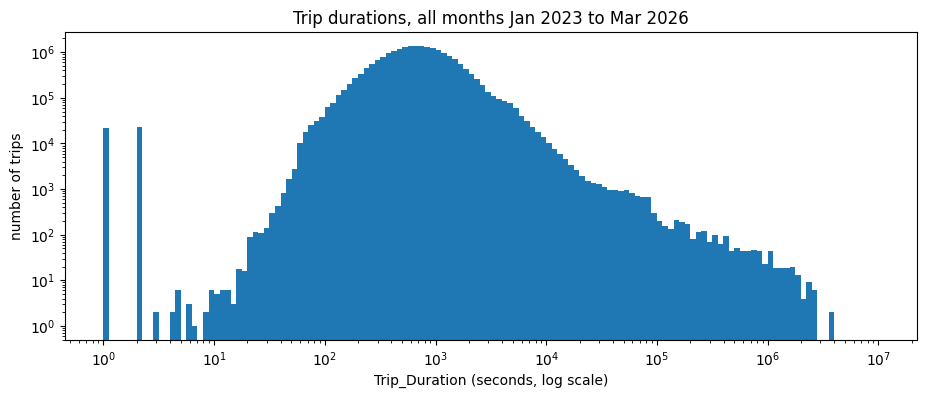

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))
plt.bar(DUR_BINS[:-1], hist_total, width=np.diff(DUR_BINS), align="edge")
plt.xscale("log")
plt.xlabel("Trip_Duration (seconds, log scale)")
plt.yscale("log")
plt.ylabel("number of trips")
plt.title("Trip durations, all months Jan 2023 to Mar 2026")
plt.show()

In [28]:
total = hist_total.sum()
for label, secs in [("1 h", 3600), ("2 h", 7200), ("3 h", 10800), ("6 h", 21600),
                    ("12 h", 43200), ("1 day", 86400), ("1 week", 604800)]:
    n = hist_total[DUR_BINS[:-1] >= secs].sum()
    print(f"longer than {label:>6}: {n:>9,.0f} trips  ({n/total:.3%})")

longer than    1 h:   398,011 trips  (1.893%)
longer than    2 h:    82,177 trips  (0.391%)
longer than    3 h:    40,181 trips  (0.191%)
longer than    6 h:    14,275 trips  (0.068%)
longer than   12 h:     7,147 trips  (0.034%)
longer than  1 day:     2,454 trips  (0.012%)
longer than 1 week:       312 trips  (0.001%)


In [29]:
for label, secs in [("3 s", 3), ("10 s", 10), ("30 s", 30), ("1 min", 60), ("2 min", 120)]:
    n = hist_total[DUR_BINS[1:] <= secs].sum()
    print(f"shorter than {label:>6}: {n:>9,.0f} trips  ({n/total:.3%})")

shorter than    3 s:    44,808 trips  (0.213%)
shorter than   10 s:    44,830 trips  (0.213%)
shorter than   30 s:    45,195 trips  (0.215%)
shorter than  1 min:    51,325 trips  (0.244%)
shorter than  2 min:   234,839 trips  (1.117%)
